# Problemas de valor inicial

In [1]:
# Librerías utilizadas en este capítulo
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from pathlib import Path
from IPython.display import HTML

## Introducción

Las ecuaciones diferenciales modelan sistemas que evolucionan. 

Nuestro ejemplo conductor es el péndulo: el ángulo $\theta(t)$ de una masa $m$ que cuelga de una barra de largo $l$, con roce viscoso de constante $\kappa$:

\begin{equation*}
ml\frac{d^2\theta}{dt^2} + \kappa l\frac{d\theta}{dt} + mg \sin \theta = 0
\end{equation*}

<img src="./images/ecuacion_pendulo.png" width="300" align= center>

En la **Unidad 8** aproximamos una derivada a partir de valores conocidos de $\theta$. Aquí buscamos determinar $\theta$ resolviendo la ecuación diferencial

### Clasificación y condiciones iniciales

La ecuación del péndulo es una **ecuación diferencial ordinaria (EDO)**: la variable dependiente $\theta$ depende de una sola variable independiente, $t$. Es **de segundo orden**, porque $\theta$ se deriva dos veces, y es **no lineal**, por el término $\sin\theta$.

Para que la solución sea única necesitamos tantas condiciones como el orden de la EDO. Si soltamos el péndulo desde el reposo con un ángulo $\theta_0$:

\begin{equation*}
\theta(0) = \theta_0, \qquad \frac{d\theta}{dt}(0) = 0
\end{equation*}

Como ambas condiciones están dadas en el mismo instante, hablamos de un **problema de valor inicial**: conocemos el estado en $t=0$ y la ecuación nos dice cómo evoluciona.

>**Importante.** La variable independiente no tiene que ser el tiempo. Por ejemplo, el modelo que representa la temperatura del agua, $T(x)$, a medida que se enfría por un tubo de largo $L$, conocida la temperatura en la entrada ($T_0$), es:
>
>\begin{equation*}
\frac{dT}{dx} = -\frac{p}{\dot{m} c_p}U_f(T-T_\infty), \qquad T(0) = T_0
\end{equation*}
>
> donde $p$, $U_f$, $\dot{m}$ y $c_p$ son constantes fisicas del problema, y $T_\infty$ es la temperatura ambiente.
>
>En este caso, la variable independiente es la posición $x$ a lo largo del tubo y la ecuación diferencial es de primer orden.

## Reducción a un sistema de primer orden

Despejando la segunda derivada, la ecuación del péndulo queda:

\begin{equation*}
\frac{d^2\theta}{dt^2} = - \frac{g}{l}\sin \theta - \frac{\kappa}{m}\frac{d\theta}{dt}
\end{equation*}

Si definimos la velocidad angular $\omega = d\theta/dt$ como una segunda incógnita, obtenemos dos ecuaciones de primer orden:

\begin{align*}
\frac{d\theta}{dt} &= \omega \\
\frac{d\omega}{dt} &= - \frac{g}{l}\sin \theta - \frac{\kappa}{m}\omega
\end{align*}

En forma vectorial, con $\mathbf{y} = \{\theta, \omega\}$:

\begin{equation*}
\frac{d\mathbf{y}}{dt} = \mathbf{F}(t,\mathbf{y}), \qquad
\mathbf{F}(t,\mathbf{y}) = \begin{Bmatrix} \omega \\ - \frac{g}{l}\sin \theta - \frac{\kappa}{m}\omega \end{Bmatrix}, \qquad
\mathbf{y}(0) = \begin{Bmatrix} \theta_0 \\ 0 \end{Bmatrix}
\end{equation*}

**Toda EDO de orden $n$ se puede escribir como un sistema de $n$ EDOs de primer orden.** Esto nos permite enfocarnos en métodos para resolver $d\mathbf{y}/dt = \mathbf{F}(t,\mathbf{y})$. 

Para simplificar la notación, desarrollaremos los métodos con una sola ecuación, $dy/dt = F(t,y)$. Todo lo que sigue se aplica igual a sistemas, reemplazando $y$ por $\mathbf{y}$.

## Método de Euler

### Método de Euler explícito

Dada la condición inicial $y(t_0)$, queremos estimar $y$ en $t_1 = t_0 + h$, con $h = \Delta t$. La forma más sencilla es una expansión de Taylor centrada en $t_0$:

\begin{equation*}
y(t_0 + h) = y(t_0) + \frac{dy}{dt}\bigg|_{t_0} h + \frac{1}{2}\frac{d^2y}{dt^2}\bigg|_{t_0} h^2 + \cdots
\end{equation*}

Como $dy/dt = F(t,y)$, truncando en el término lineal y repitiendo el procedimiento paso a paso obtenemos el **método de Euler explícito**:

\begin{equation*}
y_{n+1} = y_n + h\,F(t_n, y_n)
\end{equation*}

donde $y_n = y(t_n)$ y $t_n = t_0 + nh$.

>**Nota.** Es lo mismo que reemplazar $dy/dt$ por la diferencia hacia adelante de la **Unidad 8**: $\left(y_{n+1}-y_n\right)/h = F(t_n, y_n)$.

Gráficamente, el método avanza desde $(t_n, y_n)$ por una recta cuya pendiente es $F(t_n,y_n)$, la pendiente al inicio del intervalo:

<img src="./images/Euler_schematic.png" width="300" align= center>

Por ejemplo, consideremos la ecuación diferencial

\begin{equation*}
\frac{dy}{dt} = e^{-2t}, \qquad y(0) = -0.5
\end{equation*}

en el intervalo $t\in[0,1]$, con $h = 0.1$ y $h = 0.01$. La solución exacta es $y(t) = -\frac{1}{2}e^{-2t}$.

In [2]:
F = lambda t, y: np.exp(-2*t)          # ecuación gobernante dy/dt = F(t,y)
y0 = -0.5                              # condición inicial
t0, tf = 0, 1                          # intervalo de tiempo
y_exact = lambda t: -0.5*np.exp(-2*t)  # solución exacta

h = 0.1: error en t = 1: 0.0447
h = 0.01: error en t = 1: 0.0043


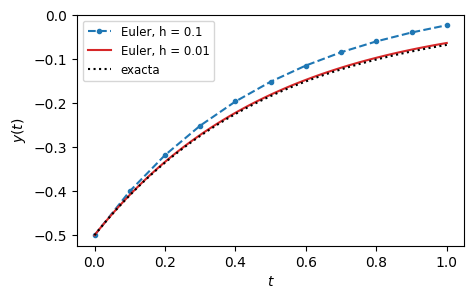

In [3]:
plt.figure(figsize=(5, 3))
for h, color in [(0.1, '#1f77b4'), (0.01, '#d62728')]:
    t = np.arange(t0, tf + h/2, h)     # tiempos t0, t1, ..., tN
    y = np.zeros(len(t))               # arreglo vacío para yn
    
    y[0] = y0                          # valor inicial
    for n in range(len(t) - 1):
        y[n+1] = y[n] + h*F(t[n], y[n])  # Euler explícito
    # calculamos error global
    print(f'h = {h}: error en t = 1: {abs(y[-1] - y_exact(tf)):.4f}')
    
    # graficamos
    plt.plot(t, y, 'o--' if h == 0.1 else '-', ms=3, color=color, label=f'Euler, h = {h}')
plt.plot(t, y_exact(t), 'k:', label='exacta')
plt.xlabel('$t$')
plt.ylabel('$y(t)$')
plt.legend(fontsize=8.5)
plt.show()

### Precisión

La solución mejora al reducir $h$, pero el error crece a medida que nos alejamos del valor inicial. Distinguimos dos tipos de error:
- **Error de truncamiento local**: el error de un solo paso, $n \rightarrow n+1$. En Euler es el término descartado de Taylor, $O(h^2)$.
- **Error de truncamiento global**: el acumulado en todo el intervalo. Para llegar a $t_f$ damos $N = (t_f - t_0)/h$ pasos, así que el error global es $N\cdot O(h^2) = O(h)$.

En el ejemplo, reducir $h$ diez veces (de 0.1 a 0.01) reduce el error global (en $t = 1$) diez veces (de 0.045 a 0.0043). Euler es un método de **primer orden**.

>**Nota.** En este ejemplo $F$ depende solo de $t$. Entonces cada paso de Euler es el área de un rectángulo de base $h$ y altura $F(t_n)$, la regla de integración de Riemman (**Unidad 7**). Volveremos a esta idea en Runge-Kutta.

### Estabilidad

Además de la precisión, un método debe ser **estable**: el error no debe crecer sin control de un paso al siguiente. La precisión depende solo del método. La estabilidad depende del método, de la EDO y de $h$.

Analicemos la ecuación

\begin{equation*}
\frac{dy}{dt} = \lambda y, \qquad \lambda = -20, \qquad y(0) = 0.5
\end{equation*}

cuya solución exacta, $y = 0.5e^{-20t}$, decae a cero. Apliquemos Euler con $h = 0.02$, $0.1$ y $0.12$.

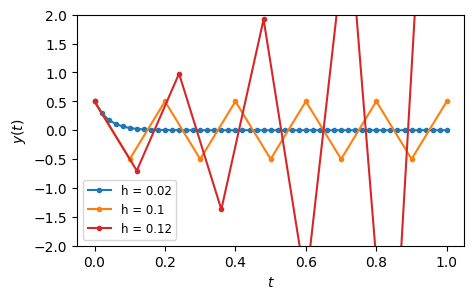

In [4]:
lam = -20                                  # constante de la EDO
F = lambda t, y: lam*y                     # ecuación gobernante
y0, t0, tf = 0.5, 0, 1

plt.figure(figsize=(5, 3))
for h, color in [(0.02, '#1f77b4'), (0.1, '#ff7f0e'), (0.12, '#d62728')]:
    
    t = np.arange(t0, tf + h/2, h)     # tiempos t0, t1, ..., tN
    y = np.zeros(len(t))               # arreglo vacío para yn
    
    y[0] = y0                          # valor inicial
    for n in range(len(t) - 1):
        y[n+1] = y[n] + h*F(t[n], y[n])    # Euler explícito
    
    # graficamos
    plt.plot(t, y, 'o-', ms=3, color=color, label=f'h = {h}')
plt.xlabel('$t$')
plt.ylabel('$y(t)$')
plt.ylim(-2, 2)
plt.legend(fontsize=8.5)
plt.show()

Con $h = 0.02$ la solución decae. Con $h = 0.1$ oscila sin decaer, y con $h=0.12$ la oscilación crece sin límite. Para entender por qué, apliquemos Euler a $dy/dt = \lambda y$:

\begin{equation*}
y_{n+1} = y_n + h\lambda y_n = (1 + h\lambda)\,y_n \quad\Rightarrow\quad y_n = (1+h\lambda)^n y_0
\end{equation*}

La solución numérica decae solo si $|1 + h\lambda| < 1$, es decir, si $h < 2/|\lambda| = 0.1$. Euler explícito es **condicionalmente estable**. Llamamos **factor de amplificación** a $R = 1+h\lambda$: el número por el que se multiplica la solución en cada paso.

>**Nota.** El factor de amplificación también se puede usar para analizar EDOs no lineales, pero ese análisis está fuera de los contenidos del curso. En la práctica, **evaluaremos la estabilidad observando la solución: una oscilación que crece sin razón física es señal de inestabilidad**.

### Método de Euler implícito

Alternativamente, podemos evaluar la pendiente al final del intervalo:

\begin{equation*}
y_{n+1} = y_n + h\,F\left(t_{n+1}, y_{n+1}\right)
\end{equation*}

El valor futuro $y_{n+1}$ aparece a ambos lados de la ecuación. Por eso llamamos a este algoritmo **método de Euler implícito**. Es equivalente a usar la diferencia hacia atrás de la **Unidad 8**.

En cada paso, $y_{n+1}$ es la raíz de

\begin{equation*}
G(y_{n+1}) = y_{n+1} - y_n - h\,F\left(t_{n+1},y_{n+1}\right) = 0
\end{equation*}

En general $F$ es no lineal, así que **cada paso es un problema de búsqueda de raíces** (**Unidad 6**).

Revisemos el ejemplo anterior con Euler implícito y $h = 0.12$, el paso que hizo explotar a Euler explícito.

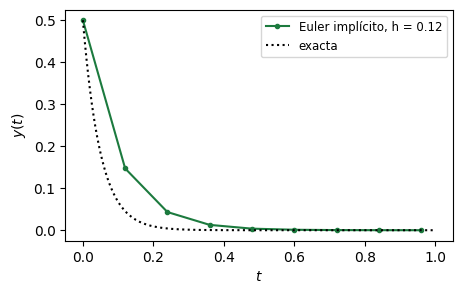

In [5]:
h = 0.12
t = np.arange(t0, tf + h/2, h)
y = np.zeros(len(t))
y[0] = y0
for n in range(len(t) - 1):
    G = lambda y1: y1 - y[n] - h*F(t[n+1], y1)   # raíz de G(y_{n+1}) = 0
    y[n+1] = fsolve(G, y[n])[0]                  # partimos desde y_n

plt.figure(figsize=(5, 3))
plt.plot(t, y, 'o-', ms=3, color='#1c7a3e', label=f'Euler implícito, h = {h}')
t_plot = np.linspace(t0, tf, 200)
plt.plot(t_plot, 0.5*np.exp(lam*t_plot), 'k:', label='exacta')
plt.xlabel('$t$')
plt.ylabel('$y(t)$')
plt.legend(fontsize=8.5)
plt.show()

> La solución decae sin oscilar. Para $dy/dt=\lambda y$, Euler implícito da $y_{n+1} = y_n/(1-h\lambda)$, y $|1/(1-h\lambda)|<1$ para todo $h$ cuando $\lambda<0$: es **incondicionalmente estable**. Su precisión sigue siendo de primer orden. Un método puede ser muy estable y poco preciso, y viceversa.

## Métodos de paso simple: Runge-Kutta

Euler usa una sola pendiente, la del inicio del intervalo, y por eso su error global es $O(h)$. Para mejorar la precisión sin reducir $h$, necesitamos una pendiente más representativa de todo el intervalo $[t_n, t_{n+1}]$.

### De la integración al paso de tiempo

Integrando la EDO entre $t_n$ y $t_{n+1}$:

\begin{equation*}
y(t_{n+1}) = y(t_n) + \int_{t_n}^{t_{n+1}} F\big(t, y(t)\big)\,dt
\end{equation*}

Si $F$ depende solo de $t$, avanzar un paso es calcular una integral, y cada regla de la **Unidad 7** da un método:

| regla de integración | paso con $F = F(t)$ |
|---|---|
| rectángulo izquierdo | $y_{n+1} = y_n + h\,F(t_n)$ (Euler) |
| punto medio | $y_{n+1} = y_n + h\,F(t_n + h/2)$ |
| trapecio | $y_{n+1} = y_n + \frac{h}{2}\left[F(t_n) + F(t_{n+1})\right]$ |
| Simpson 1/3 | $y_{n+1} = y_n + \frac{h}{6}\left[F(t_n) + 4F(t_n + h/2) + F(t_{n+1})\right]$ |

Cuando $F$ depende también de $y$ aparece un problema: para evaluar $F$ en $t_n + h/2$ o en $t_{n+1}$ necesitamos $y$ en ese instante, y no lo conocemos. La solución es **estimarlo con un paso de Euler** y usar esa estimación solo para evaluar la pendiente. Esa es la idea de los métodos de Runge-Kutta.

### Forma general

Los métodos de Runge-Kutta (RK) son una familia de métodos iterativos, explícitos e implícitos, desarrollados por C. Runge y M. W. Kutta alrededor de 1900. Un método RK de $s$ etapas tiene la forma:

\begin{equation*}
y_{n+1} = y_n + h\sum_{i=1}^{s} b_i k_i
\end{equation*}

\begin{equation*}
k_i = F\left(t_n + c_i h,\; y_n + h\sum_{j=1}^{s} a_{ij} k_j\right), \qquad i = 1, \dots, s
\end{equation*}

Cada $k_i$ es una aproximación local de la pendiente, evaluada en un punto intermedio del intervalo. El paso usa un promedio ponderado de esas pendientes, con pesos $b_i$. Los coeficientes $a_{ij}$, $b_i$ y $c_i$ definen el método y dependen de la regla de cuadratura que se quiere reproducir.

>**Nota.** El método es **explícito** si $a_{ij} = 0$ para $j \geq i$: cada $k_i$ se calcula con los $k_j$ anteriores, uno tras otro. En caso contrario es **implícito**: los $k_i$ aparecen a ambos lados y en cada paso hay que resolver un sistema de ecuaciones, igual que en Euler implícito.

### Métodos de dos etapas

Con $s=2$ y la forma explícita:

\begin{align*}
k_1 &= F(t_n, y_n) \\
k_2 &= F(t_n + c_2 h,\; y_n + h\,a_{21}k_1) \\
y_{n+1} &= y_n + h\left(b_1 k_1 + b_2 k_2\right)
\end{align*}

$k_1$ es la pendiente al inicio del intervalo. $k_2$ es la pendiente en un punto intermedio, donde $y$ se estima con un paso de Euler que usa $k_1$, es decir, con la serie de Taylor truncada a primer orden.

Existe una familia de métodos RK2. Todos tienen error local $O(h^3)$ y global $O(h^2)$.

**Método de Heun** ($b_2 = \tfrac{1}{2}$, $c_2 = a_{21} = 1$): promedia la pendiente al inicio y la pendiente al final, estimada con Euler.

\begin{equation*}
k_1 = F(t_n,y_n), \qquad k_2 = F(t_n+h,\; y_n+hk_1), \qquad y_{n+1} = y_n + \frac{h}{2}\left(k_1+k_2\right)
\end{equation*}

Si $F$ depende solo de $t$, es la regla del trapecio.

<img src="./images/Heun_method.png" width="500" align= center>

**Método del punto medio** ($b_2 = 1$, $c_2 = a_{21} = \tfrac{1}{2}$): avanza medio paso con Euler y usa la pendiente de ese punto para el paso completo.

\begin{equation*}
k_1 = F(t_n,y_n), \qquad k_2 = F\left(t_n+\tfrac{h}{2},\; y_n+\tfrac{h}{2}k_1\right), \qquad y_{n+1} = y_n + h\,k_2
\end{equation*}

Si $F$ depende solo de $t$, es la regla del punto medio.

<img src="./images/Midpoint_method.png" width="500" align= center>

### Runge-Kutta de cuarto orden (RK4)

RK4 es el miembro más usado de la familia, al punto que muchas veces se le llama simplemente "el método de Runge-Kutta":

\begin{equation*}
y_{n+1} = y_n + \frac{h}{6}\left(k_1+2k_2+2k_3+k_4\right)
\end{equation*}

\begin{align*}
k_1 &= F(t_n,y_n) \\
k_2 &= F\left(t_n+\tfrac{h}{2},\; y_n+\tfrac{h}{2}k_1\right) \\
k_3 &= F\left(t_n+\tfrac{h}{2},\; y_n+\tfrac{h}{2}k_2\right) \\
k_4 &= F\left(t_n+h,\; y_n+hk_3\right)
\end{align*}

El paso es $h$ por una pendiente estimada, que es el promedio ponderado de cuatro pendientes:
- $k_1$ es la pendiente al inicio del intervalo.
- $k_2$ es la pendiente en el punto medio, con $y$ estimado a partir de $k_1$ (Euler).
- $k_3$ es otra vez la pendiente en el punto medio, ahora con $y$ estimado a partir de $k_2$.
- $k_4$ es la pendiente al final del intervalo, con $y$ estimado a partir de $k_3$.

El promedio da más peso a las pendientes del punto medio. Si $F$ depende solo de $t$, entonces $k_2 = k_3$ y RK4 es exactamente Simpson 1/3. RK4 tiene error local $O(h^5)$ y error global $O(h^4)$: es un método de **cuarto orden**.

### Orden y costo

Comprobemos el orden de Euler, Heun y RK4 con el ejemplo 25.8 de Chapra y Canale:

\begin{equation*}
\frac{dy}{dt} = 4e^{0.8t} - 0.5y, \qquad y(0) = 2, \qquad y(4) = 75.33896
\end{equation*}

In [6]:
def euler(F, t, y, h):
    return y + h*F(t, y)

def heun(F, t, y, h):
    k1 = F(t, y)
    k2 = F(t + h, y + h*k1)
    return y + h/2*(k1 + k2)

def rk4(F, t, y, h):
    k1 = F(t, y)
    k2 = F(t + h/2, y + h/2*k1)
    k3 = F(t + h/2, y + h/2*k2)
    k4 = F(t + h, y + h*k3)
    return y + h/6*(k1 + 2*k2 + 2*k3 + k4)

In [7]:
def resolver(paso, F, t0, tf, y0, h):
    '''Aplica un método Runge-Kutta con h fijo..'''
    N = int(round((tf - t0)/h))
    t = t0 + h*np.arange(N + 1)
    y = np.zeros((N + 1,) + np.shape(y0))
    y[0] = y0
    for n in range(N):
        y[n+1] = paso(F, t[n], y[n], h)
    return t, y

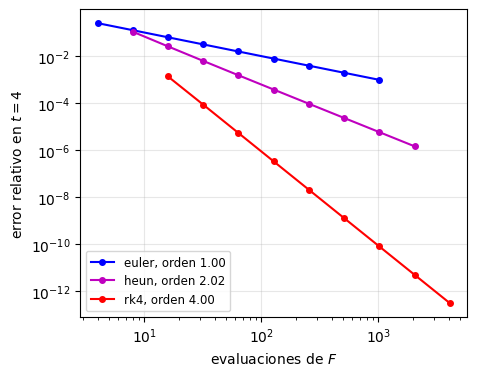

In [8]:
F = lambda t, y: 4*np.exp(0.8*t) - 0.5*y
y_exact = 75.33896260915857                       # y(t = 4)
h_array = 4/2**np.arange(2, 11)                   # h desde 1 hasta 1/256

plt.figure(figsize=(5, 4))
for RK, n_eval, color in [(euler, 1, 'b'), (heun, 2, 'm'), (rk4, 4, 'r')]:
    
    error_rel = np.zeros_like(h_array)                 # arreglo dummy tamaño h_array
    for i, h in enumerate(h_array):
        t, y = resolver(RK, F, 0, 4, 2.0, h)           # resolvemos dydt = F(t, y)
        y_approx = y[-1]                               # aproximado de y(t = 4)
        error_rel[i] = abs(y_approx - y_exact)/y_exact # error relativo
    
    # determinamos el orden mediante regresión lineal del modelo E = Ah^n
    orden = np.polyfit(np.log(h_array), np.log(error_rel), 1)[0]
    
    # graficamos
    plt.loglog(n_eval*4/h_array, error_rel, 'o-', ms=4, color=color,
               label=f'{RK.__name__}, orden {orden:.2f}')
    
plt.xlabel('evaluaciones de $F$')
plt.ylabel('error relativo en $t = 4$')
plt.legend(fontsize=8.5)
plt.grid(alpha=0.3)
plt.show()

Las pendientes en $h$ (obtenidas con `polyfit`, **Unidad 3**) son 1, 2 y 4. 

Graficamos contra el número de evaluaciones de $F$, que es el costo real. Con 1024 evaluaciones, Euler llega a un error de $10^{-3}$, Heun a $6\times10^{-6}$ y RK4 a $8\times10^{-11}$. RK4 evalúa cuatro veces por paso, pero gana con holgura.

### Tabla de Butcher

Los coeficientes de un método RK se ordenan en una **tabla de Butcher**: los nodos $c_i$ a la izquierda, la matriz $A = [a_{ij}]$ al centro y los pesos $b_i$ abajo.

\begin{equation*}
\begin{array}{c|cccc}
c_1 & a_{11} & a_{12} & \cdots & a_{1s} \\
c_2 & a_{21} & a_{22} & \cdots & a_{2s} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
c_s & a_{s1} & a_{s2} & \cdots & a_{ss} \\
\hline
 & b_1 & b_2 & \cdots & b_s
\end{array}
\end{equation*}

Los métodos que hemos visto quedan así:

\begin{equation*}
\underset{\text{Euler}}{\begin{array}{c|c} 0 & 0 \\ \hline & 1 \end{array}}
\qquad
\underset{\text{Heun}}{\begin{array}{c|cc} 0 & 0 & 0\\ 1 & 1 & 0 \\ \hline & \frac{1}{2} & \frac{1}{2} \end{array}}
\qquad
\underset{\text{Punto medio}}{\begin{array}{c|cc} 0 & 0 & 0\\ \frac{1}{2} & \frac{1}{2} & 0 \\ \hline & 0 & 1 \end{array}}
\qquad
\underset{\text{RK4}}{\begin{array}{c|cccc} 0 & 0&0&0&0 \\ \frac{1}{2} & \frac{1}{2} &0&0&0 \\ \frac{1}{2} & 0 & \frac{1}{2} &0&0 \\ 1 & 0 & 0 & 1 &0 \\ \hline & \frac{1}{6} & \frac{1}{3} & \frac{1}{3} & \frac{1}{6} \end{array}}
\end{equation*}

La forma de $A$ dice el tipo de método. En los métodos explícitos $A$ es estrictamente triangular inferior: ceros en la diagonal y sobre ella. En los implícitos $A$ tiene términos en la diagonal o sobre ella, como el método `Radau` que veremos en la sección de rigidez.

La tabla también es la forma práctica de implementar RK: una sola función ejecuta cualquier método explícito a partir de su tabla. Probémosla con la tabla de RK4 en el ejemplo anterior:

In [9]:
def paso_rk(F, t, y, h, A, b, c):
    '''Un paso de un método RK explícito definido por su tabla de Butcher.'''
    k = []
    for i in range(len(b)):
        y_i = y + h*sum(A[i][j]*k[j] for j in range(i))   # solo k anteriores
        k.append(F(t + c[i]*h, y_i))
    return y + h*sum(b[i]*k[i] for i in range(len(b)))

A_rk4 = [[0, 0, 0, 0], [1/2, 0, 0, 0], [0, 1/2, 0, 0], [0, 0, 1, 0]]
b_rk4, c_rk4 = [1/6, 1/3, 1/3, 1/6], [0, 1/2, 1/2, 1]

paso = lambda F, t, y, h: paso_rk(F, t, y, h, A_rk4, b_rk4, c_rk4)
print(f'y(4) con la tabla de RK4: {resolver(paso, F, 0, 4, 2.0, 0.5)[1][-1]:.8f}')
print(f'y(4) con la función rk4:  {resolver(rk4, F, 0, 4, 2.0, 0.5)[1][-1]:.8f}')

y(4) con la tabla de RK4: 75.34533606
y(4) con la función rk4:  75.34533606


Algunos métodos agregan una segunda fila de pesos, $\hat{b}_i$. Con las mismas pendientes $k_i$ se obtienen dos estimaciones de distinto orden, $y_{n+1}$ y $\hat{y}_{n+1}$. Su diferencia estima el error del paso, y el método ajusta $h$ para mantenerlo bajo una tolerancia. Se llaman **métodos embebidos**. El método por defecto de `solve_ivp`, `RK45` (Dormand-Prince, órdenes 5 y 4), funciona así. Más info [acá](https://en.wikipedia.org/wiki/Runge%E2%80%93Kutta%E2%80%93Fehlberg_method)

>**Nota.** Es la misma idea de la cuadratura adaptativa de la **Unidad 7**: `quad` compara dos reglas (Gauss y Kronrod) que comparten evaluaciones de la función para estimar el error sin costo extra.

## Métodos multipaso

Los métodos de Runge-Kutta son **de paso simple**: para calcular $y_{n+1}$ usan solo $y_n$, y descartan los valores anteriores. Las pendientes intermedias $k_i$ se calculan y se botan en cada paso.

Los **métodos multipaso** reutilizan la historia, $y_{n-1}, y_{n-2}, \dots$ Con ella construyen un polinomio de interpolación (**Unidad 4**) y obtienen un método de alto orden con una sola evaluación nueva de $F$ por paso.

### Adams-Bashforth

Interpolamos las pendientes ya calculadas, $F_{n-1}$ y $F_n$, con una recta, y la integramos sobre $[t_n, t_{n+1}]$ (**Unidad 7**):

\begin{equation*}
y_{n+1} = y_n + h\left(\frac{3}{2}F_n - \frac{1}{2}F_{n-1}\right)
\end{equation*}

Es el método de Adams-Bashforth de dos pasos (AB2). Es explícito, de segundo orden como Heun, y evalúa $F$ una vez por paso en vez de dos.

### Fórmulas de diferenciación hacia atrás (BDF)

En vez de integrar $F$, interpolamos los valores $y_{n-1}$, $y_n$ y el desconocido $y_{n+1}$, y exigimos que la derivada del polinomio en $t_{n+1}$ sea igual a $F$. Es la diferencia hacia atrás de orden $O(h^2)$ de la tabla de la **Unidad 8**:

\begin{equation*}
\frac{3y_{n+1} - 4y_n + y_{n-1}}{2h} = F\left(t_{n+1}, y_{n+1}\right)
\end{equation*}

Es el método BDF de dos pasos (BDF2). Con un solo paso, la misma idea da Euler implícito (BDF1). Como $y_{n+1}$ aparece en $F$, BDF es implícito, es decir, **cada paso es una búsqueda de raíces** (**Unidad 6**). A cambio, es muy estable, y por eso `solve_ivp` lo ofrece para problemas rígidos.

En la siguiente animación, avancemos paso a paso con AB2 y con BDF2. Observemos qué puntos pasados usa cada método, el polinomio que construye con ellos y cómo obtiene el punto nuevo.

In [10]:
HTML(Path('interactive/A3_multipaso.html').read_text(encoding='utf-8'))

En la animación, vemos que AB2 extrapola la recta de pendientes hacia el intervalo nuevo e integra bajo ella, mientras que BDF2 busca el $y_{n+1}$ para el cual la parábola que pasa por los tres puntos tiene la pendiente correcta al final.

Los métodos multipaso tienen dos desventajas: (1) no pueden partir solos, porque en $t_0$ no hay historia, así que los primeros pasos se calculan con un método de paso simple; (2) cambiar $h$ obliga a reconstruir el polinomio con datos no equiespaciados.

## Solución de EDOs en Python (`scipy.integrate.solve_ivp`)

La función `solve_ivp` de `scipy.integrate` resuelve sistemas de EDOs con valor inicial. Sus argumentos mínimos son:
```python
from scipy.integrate import solve_ivp
sol = solve_ivp(fun, t_span, y0)
```

donde:
- `fun`: (*callable*) función $\mathbf{F}(t,\mathbf{y})$.
- `t_span = (t0, tf)`: (*tuple*) tiempo inicial y final.
- `y0`: (*array*) condición inicial $\mathbf{y}(t_0)$.

El argumento `method` permite elegir entre los siguientes métodos:
- `'RK45'`: Runge-Kutta explícito embebido de órdenes 5 y 4 (Dormand-Prince). **Método por defecto**.
- `'RK23'`: Runge-Kutta explícito embebido de órdenes 3 y 2 (Bogacki-Shampine).
- `'DOP853'`: Runge-Kutta explícito de orden 8.
- `'Radau'`: Runge-Kutta implícito de orden 5 (Radau IIA).
- `'BDF'`: multipaso implícito (fórmulas de diferenciación hacia atrás).
- `'LSODA'`: alterna automáticamente entre Adams y BDF.

Todos ajustan $h$ en cada paso para cumplir la tolerancia de error relativo (`rtol`) y absoluto (`atol`):
```python
sol = solve_ivp(fun, t_span, y0, rtol=1E-8, atol=1E-8)
```
>Por defecto, `rtol=1E-3` y `atol=1E-6`.

Resolvamos el péndulo con $m = 0.1$ kg, $l = 0.3$ m, $\kappa = 0.05$ kg/s y $\theta_0 = 30°$, en el intervalo $t\in[0,5]$ s.

In [11]:
m, l, kappa, g = 0.1, 0.3, 0.05, 9.8   # masa (kg), largo (m), roce (kg/s), gravedad (m/s2)

def F(t, y):
    theta, omega = y
    return [omega,                                       # d(theta)/dt
            -g/l*np.sin(theta) - kappa/m*omega]          # d(omega)/dt

y0 = [np.radians(30), 0]                                 # condición inicial
sol = solve_ivp(F, (0, 5), y0)
print(sol.message)
print(f'Pasos de tiempo: {sol.t.size}, evaluaciones de F: {sol.nfev}')

The solver successfully reached the end of the integration interval.
Pasos de tiempo: 35, evaluaciones de F: 212


La solución está en `sol.t` (tiempos) y `sol.y` (una fila por variable: `sol.y[0]` es $\theta$ y `sol.y[1]` es $\omega$). La descripción de todos los atributos está en la [documentación oficial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).

Notemos que no indicamos $h$: `solve_ivp` elige los tiempos `sol.t` y los ajusta en cada paso. Para obtener la solución en tiempos específicos usamos el argumento `t_eval`, y la función interpola entre sus propios pasos.

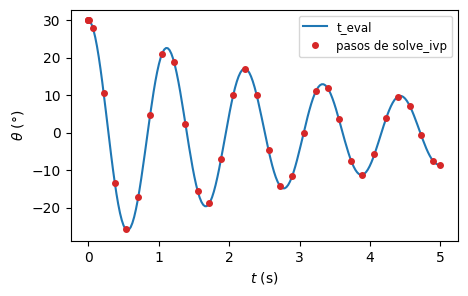

In [12]:
t_plot = np.linspace(0, 5, 200)                          # tiempos para graficar
sol_plot = solve_ivp(F, (0, 5), y0, t_eval=t_plot)

plt.figure(figsize=(5, 3))
plt.plot(sol_plot.t, np.degrees(sol_plot.y[0]), '-', color='#1f77b4', label='t_eval')
plt.plot(sol.t, np.degrees(sol.y[0]), 'o', ms=4, color='#d62728', label='pasos de solve_ivp')
plt.xlabel('$t$ (s)')
plt.ylabel(r'$\theta$ (°)')
plt.legend(fontsize=8.5)
plt.show()

> Con la tolerancia por defecto, `solve_ivp` usa 35 pasos de ~0.15 s, unos 7 por oscilación. Los puntos de `t_eval` no cambian esos pasos: se obtienen por interpolación entre ellos.

## Rigidez en EDOs

Una EDO es **rígida** si una de sus componentes cambia muy rápido respecto a otra. Esto provoca problemas de estabilidad en la solución numérica.

Consideremos por ejemplo la ecuación

\begin{equation*}
\frac{dy}{dt} = - 1000y + 3000 - 2000e^{-t}, \qquad y(0) = 0
\end{equation*}

cuya solución analítica es

\begin{equation*}
y(t) = 3 - 0.998e^{-1000t} - 2.002e^{-t}
\end{equation*}

A partir de la solución vemos que, al comienzo ($t < 0.005$), la respuesta está dominada por el término transitorio $e^{-1000t}$. Luego ese término desaparece y la respuesta queda dominada por $e^{-t}$, que cambia lentamente.

El método numérico no conoce la solución analítica. Aunque el transitorio dure solo 0.005 s, un método explícito necesita un $h$ muy pequeño durante **toda** la simulación para no volverse inestable.

En la siguiente animación, vemos que con $h = 0.0015$ todos los métodos siguen la solución exacta, pero necesitan 2667 pasos. Con $h = 0.05$ (80 pasos), Euler explícito y RK4 se vuelven inestables. Los métodos implícitos siguen estables y llegan a $t = 4$ con un error menor que $10^{-6}$.

In [13]:
HTML(Path('interactive/A2_estabilidad_rigidez.html').read_text(encoding='utf-8'))

>**Nota.** Usar botón "ver transitorio" para hacer un zoom en $t < 0.005$



**En un problema rígido, es la estabilidad y no la precisión la que obliga a un método explícito a usar un $h$ pequeño.**

### Recomendaciones

- **Para EDOs no rígidas**, se recomiendan los métodos explícitos `RK45`, `RK23` y `DOP853`.
- **Para EDOs rígidas**, se recomiendan los métodos implícitos `Radau` y `BDF`.

Como regla general, conviene partir con un método explícito (`RK45`). Si la solución tarda demasiado, necesita una cantidad enorme de pasos u oscila sin razón física, probablemente la EDO es rígida. En ese caso, cambiamos a un método implícito de paso simple (`Radau`) o multipaso (`BDF`).

Revisemos esto con la siguiente EDO en el intervalo $t\in[0,10]$:

\begin{equation*}
\frac{dy}{dt} = - 100000\left(y - \cos t\right),\quad y(0) = 1
\end{equation*}

Compararemos el número de pasos y de evaluaciones de $F$ de `RK45` (explícito de paso simple), `Radau` (implícito de paso simple) y `BDF` (implícito multipaso).

In [14]:
F = lambda t, y: -100000*(y - np.cos(t))

sol = {}
for metodo in ['RK45', 'Radau', 'BDF']:
    sol[metodo] = solve_ivp(F, (0, 10), [1], method=metodo)
    print(f'{metodo:>5}: {sol[metodo].t.size:7d} pasos, {sol[metodo].nfev:8d} evaluaciones de F')

 RK45:  302037 pasos,  2113262 evaluaciones de F
Radau:       7 pasos,       44 evaluaciones de F
  BDF:      56 pasos,      160 evaluaciones de F


> `RK45` necesita más de 300 000 pasos para no volverse inestable. `Radau` y `BDF`, al ser implícitos, resuelven el problema en 7 y 56 pasos. Lo que resuelve la rigidez es que el método sea implícito, no que sea de paso simple o multipaso.

Revisemos gráficamente la solución de cada método. Los puntos marcan los pasos que usa cada método para llegar a $t = 10$.

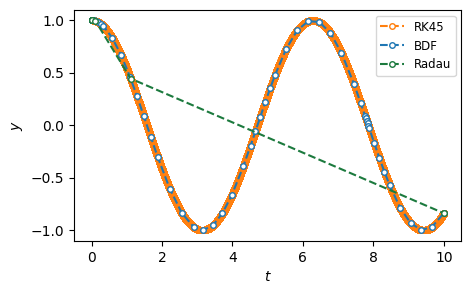

In [15]:
plt.figure(figsize=(5, 3))
for metodo, color in [('RK45', '#ff7f0e'), ('BDF', '#1f77b4'), ('Radau', '#1c7a3e')]:
    plt.plot(sol[metodo].t, sol[metodo].y[0], '--o', ms=4, mfc='w', color=color, label=metodo)
plt.xlabel('$t$')
plt.ylabel('$y$')
plt.legend(fontsize=8.5)
plt.show()

> `RK45` usa tantos pasos que sus marcadores se superponen y forman una línea. `Radau` usa pasos cortos en las primeras iteraciones y luego pasos muy largos para llegar a $t = 10$.

Analicemos ahora la solución en todo el intervalo, pidiéndola en 51 tiempos con `t_eval` ($\Delta t = 0.2$):

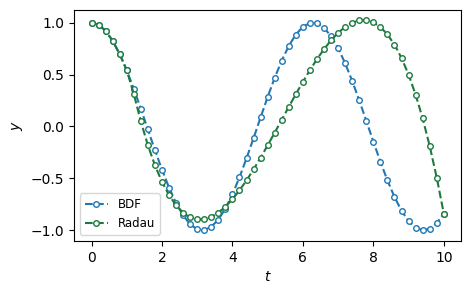

In [16]:
t_plot = np.linspace(0, 10, 51)

plt.figure(figsize=(5, 3))
for metodo, color in [('BDF', '#1f77b4'), ('Radau', '#1c7a3e')]:
    sol_eval = solve_ivp(F, (0, 10), [1], method=metodo, t_eval=t_plot)
    plt.plot(t_plot, sol_eval.y[0], '--o', ms=4, mfc='w', color=color, label=metodo)
plt.xlabel('$t$')
plt.ylabel('$y$')
plt.legend(fontsize=8.5)
plt.show()

Las curvas no coinciden. La solución de `BDF` es la correcta: después del transitorio, $y$ sigue a $\cos t$.

Esto ocurre porque **`t_eval` no modifica el paso adaptativo del método**. Los valores en `t_eval` se obtienen por interpolación entre los pasos propios del método, y los últimos pasos de `Radau` son tan largos que la interpolación entre ellos es pobre.

> `Radau` fue el más eficiente para llegar a $y(t_f)$, pero no necesariamente el más preciso en todo el intervalo. Si necesitamos la solución en todo $[t_0, t_f]$, conviene reducir `rtol` o limitar el paso con el argumento `max_step`.

## Resumen: ¿qué método uso?

| Situación | Método | En Python |
|---|---|---|
| EDO no rígida, uso general | RK explícito adaptativo | `method='RK45'` |
| no rígida, alta precisión | RK explícito de orden 8 | `method='DOP853'` |
| EDO rígida | implícito | `method='Radau'` o `'BDF'` |
| no sabemos si es rígida | cambio automático | `method='LSODA'` |
| paso fijo (enseñanza, tiempo real) | RK4 | programado a mano |

Antes de confiar en la solución de una EDO conviene revisar:
1. ¿Cambia la solución al reducir `rtol`? Si cambia, aún no convergió.
2. ¿`RK45` necesita una cantidad enorme de pasos? Probablemente la EDO es rígida.
3. ¿Los resultados en `t_eval` dependen de la interpolación entre pasos largos?

## Referencias
- Chapra S., Canale R. **Capítulo 25: Métodos de Runge-Kutta** en *Métodos Numéricos para Ingenieros*, 7ma Ed., McGraw Hill, 2015.
  - §25.1 método de Euler · §25.2 Heun y punto medio · §25.3 métodos de Runge-Kutta (ejemplo 25.8) · §25.4 sistemas de ecuaciones · §25.5 métodos adaptativos

- Chapra S., Canale R. **Capítulo 26: Métodos rígidos y de pasos múltiples** en *Métodos Numéricos para Ingenieros*, 7ma Ed., McGraw Hill, 2015.
  - §26.1 rigidez · §26.2 métodos de pasos múltiples

- Press W. H., Teukolsky S. A., Vetterling W. T., Flannery B. P. **Chapter 17: Integration of Ordinary Differential Equations** in *Numerical Recipes: The Art of Scientific Computing*, 3rd Ed., Cambridge University Press, 2007.

- Kong Q., Siauw T., Bayen A. M. **Chapter 22: Ordinary Differential Equations (ODEs) Initial-Value Problems** in *[Python Programming and Numerical Methods – A Guide for Engineers and Scientists](https://pythonnumericalmethods.berkeley.edu/notebooks/chapter22.00-ODE-Initial-Value-Problems.html)*, 1st Ed., Academic Press, 2021.